### 1. Import Library

In [1]:
#202431013_Tashfia Wahdah Fuady
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

### 2. Membaca Dataset

In [2]:
#202431013_Tashfia Wahdah Fuady
df = pd.read_csv("data_sekolah_indonesia_final.csv")
display(df.head())

print("\nUkuran dataset:")
print(df.shape)

,Provinsi,Kabupaten_Kota,SD_Negeri,SD_Swasta,Jumlah_SD,SMP_Negeri,SMP_Swasta,Jumlah_SMP,SMA_Negeri,SMA_Swasta,Jumlah_SMA,SMK_Negeri,SMK_Swasta,Jumlah_SMK,Total_Seluruh_Sekolah
0,Tidak diketahui,Kab. Aceh Besar,247.0,15,262,60,48,108,34,34,68,8,3,11,449
1,Tidak diketahui,Kab. Pidie,325.0,14,339,65,35,100,32,19,51,7,7,14,504
2,Tidak diketahui,Kab. Aceh Utara,395.0,17,412,107,85,192,43,39,82,14,10,24,710
3,Tidak diketahui,Kab. Aceh Timur,317.0,18,335,82,30,112,32,16,48,14,1,15,510
4,Tidak diketahui,Kab. Aceh Tengah,207.0,19,226,50,21,71,21,15,36,4,1,5,338



Ukuran dataset:
(481, 15)


### 3. Menghapus Data Kosong

In [5]:
#202431013_Tashfia Wahdah Fuady
kolom = ["Jumlah_SMP", "Jumlah_SMA", "Jumlah_SMK", "Jumlah_SD"]

df = df.dropna(subset=kolom)

print("Jumlah data setelah dropna:", len(df))
print("Jumlah data kosong:")
print(df[kolom].isnull().sum())

Jumlah data setelah dropna: 481
Jumlah data kosong:
Jumlah_SMP    0
Jumlah_SMA    0
Jumlah_SMK    0
Jumlah_SD     0
dtype: int64


### 4. Menentukan Fitur (X) dan Target (Y)

In [8]:
X = df[["Jumlah_SMP", "Jumlah_SMA", "Jumlah_SMK"]]
y = df["Jumlah_SD"]

print("Fitur (X):")
display(X.head())

print("\nTarget (Y):")
display(y.head())

Fitur (X):


,Jumlah_SMP,Jumlah_SMA,Jumlah_SMK
0,108,68,11
1,100,51,14
2,192,82,24
3,112,48,15
4,71,36,5



Target (Y):


0    262
1    339
2    412
3    335
4    226
Name: Jumlah_SD, dtype: int64

### 5. Membagi Data Latih dan Data Uji

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 384
Jumlah data uji: 97


### 6. Membuat Model Linear Regression

In [10]:
model = LinearRegression()

print("Model Linear Regression berhasil dibuat.")

Model Linear Regression berhasil dibuat.


### 7. Melatih Model

In [11]:
model.fit(X_train, y_train)

print("Model berhasil dilatih.")

Model berhasil dilatih.


### 8. Melakukan Prediksi Data Uji

In [12]:
y_pred = model.predict(X_test)

print("Hasil prediksi:")
print(y_pred[:10])

Hasil prediksi:
[ 177.11721035  170.99717721 1588.50543493  261.93085779  923.71214621
  932.21552399  154.82429849  158.3306157   126.18558771  135.77419409]


### 9. Evaluasi Model

In [14]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Koefisien:", model.coef_)
print("Intercept:", model.intercept_)
print("MSE:", mse)
print("R2 Score:", r2)

Koefisien: [ 2.95656414 -2.5912003   1.43872181]
Intercept: 79.33165707312594
MSE: 12360.360707862996
R2 Score: 0.8717985518782051


### 10. Menampilkan Persamaan Regresi Linear

In [15]:
a = model.intercept_
b1, b2, b3 = model.coef_

print("Persamaan Regresi Linear:")
print(
    f"Y = {a:.4f} + ({b1:.4f} × X1) "
    f"+ ({b2:.4f} × X2) + ({b3:.4f} × X3)"
)

Persamaan Regresi Linear:
Y = 79.3317 + (2.9566 × X1) + (-2.5912 × X2) + (1.4387 × X3)


## Visualisasi hasil regresi

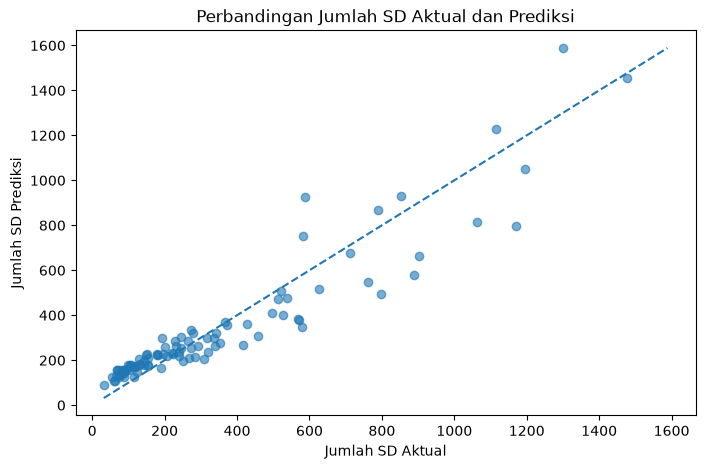

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Jumlah SD Aktual")
plt.ylabel("Jumlah SD Prediksi")
plt.title("Perbandingan Jumlah SD Aktual dan Prediksi")

# Garis pembanding
batas_min = min(y_test.min(), y_pred.min())
batas_max = max(y_test.max(), y_pred.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle="--"
)

plt.show()